In [7]:
from figs_output import fig_output 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from datasets.Harmonized_Datasets import harmonize
from scipy.stats import wilcoxon, ttest_ind
from statsmodels.stats.multitest import multipletests
from starbars import draw_annotation


In [8]:
pipeline_results_dir = fig_output + "pipeline_output/"
gmt_dir = "../../data/GMT/"
hallmark_gmt = gmt_dir + "h.all.v2026.1.Hs.symbols.gmt"

model_name = "lr_reg"
model_cv_metrics = {}
model_ev_metrics = {}


datasets = harmonize()
mf_ad = datasets["Moffitt"]
dc_ad = datasets["Decampos"]

cv_results= pd.read_csv(f"{pipeline_results_dir}{model_name}_cv_results.csv").set_index('samples')
ev_results = pd.read_csv(f"{pipeline_results_dir}{model_name}_ev_results.csv").set_index('samples')

mf_ad = mf_ad[cv_results.index]
dc_ad = dc_ad[ev_results.index]

mf_ad.obs['y_pred'] = cv_results['y_pred']
dc_ad.obs['y_pred'] = ev_results['y_pred']

mf_ad = mf_ad[mf_ad.obs['t11_14'].notna()]
mf_ad.obs['t11_14'] = mf_ad.obs['t11_14'].astype(int)

mf_ad.obs['t11_14'] = pd.Categorical(mf_ad.obs['t11_14'], categories=[0,1], ordered=True)
mf_ad.obs['y_pred'] = pd.Categorical(mf_ad.obs['y_pred'], categories=[0,1], ordered=True)
dc_ad.obs['y_pred'] = pd.Categorical(dc_ad.obs['y_pred'], categories=[0,1], ordered=True)

adatas = [mf_ad, mf_ad]

labels = ["t11_14", 'y_pred']
genes_of_interest = ["BCL2", "MCL1","BCL2L1", "BBC3", "NOXA1", "CCND1"]
titles = ['t11;14 Status', "Model Predictions", 'Model Predictions (External Validation)']
mappers = {'y_pred': {0: 'Resistant', 1:"Sensitive"},
           't11_14': {0: "t11;14 -", 1:"t11;14 +"}
           }


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18680


/tmp/ipykernel_23737/1747541181.py:20: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  mf_ad.obs['y_pred'] = cv_results['y_pred']
/tmp/ipykernel_23737/1747541181.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  dc_ad.obs['y_pred'] = ev_results['y_pred']
/tmp/ipykernel_23737/1747541181.py:24: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  mf_ad.obs['t11_14'] = mf_ad.obs['t11_14'].astype(int)


                pval       stat          padj
gene                                         
BCL2    1.358212e-01  -1.523023  1.629854e-01
MCL1    3.715209e-01   0.904048  3.715209e-01
BCL2L1  1.176688e-01   1.600003  1.629854e-01
BBC3    1.072610e-02  -2.680106  2.145221e-02
NOXA1   6.123407e-03  -2.898609  1.837022e-02
CCND1   1.742714e-12 -10.136071  1.045628e-11
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
            pval      stat      padj
gene                                
BCL2    0.800589 -0.254314  0.943097
MCL1    0.814310  0.236465  0.943097
BCL2L1  0.005804  2.919034  0.034826
BBC3    0.943097 -0.071839  0.943097
NOXA1   0.480480 -0.712364  0.943097
CCND1   0.136576 -1.520005  0.409729
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03


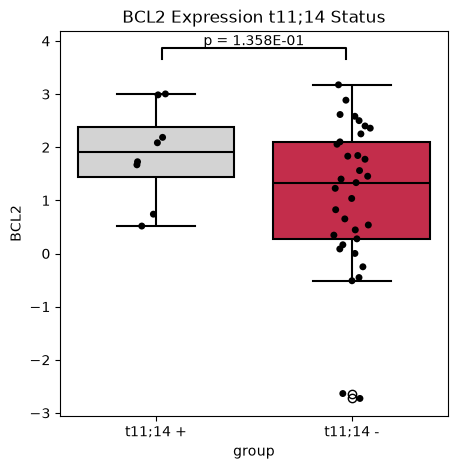

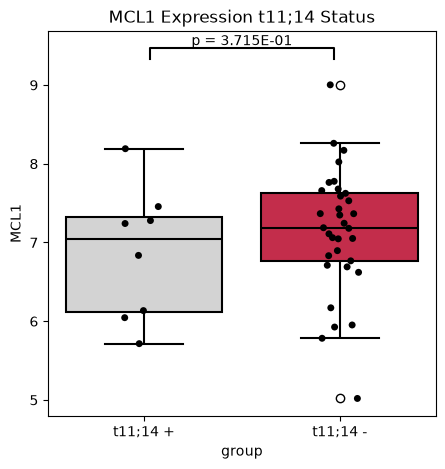

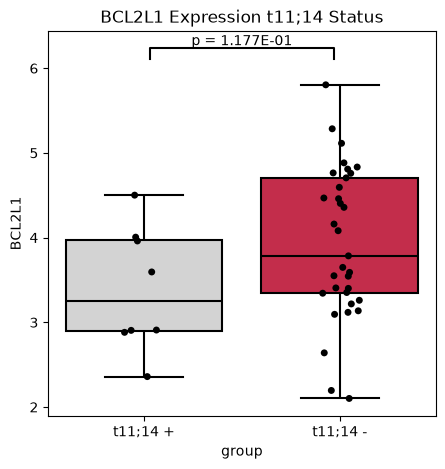

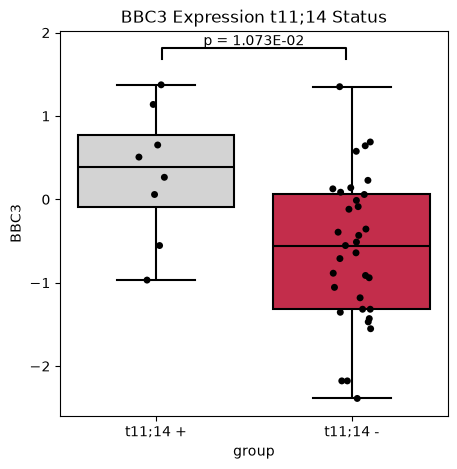

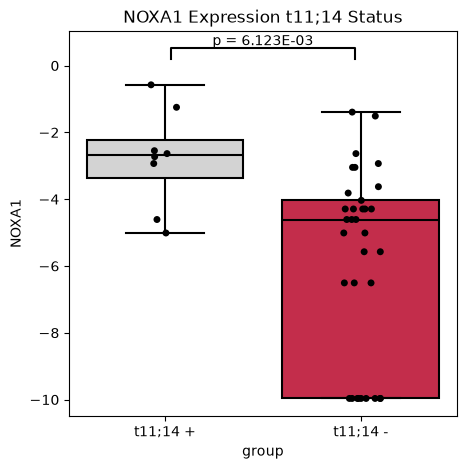

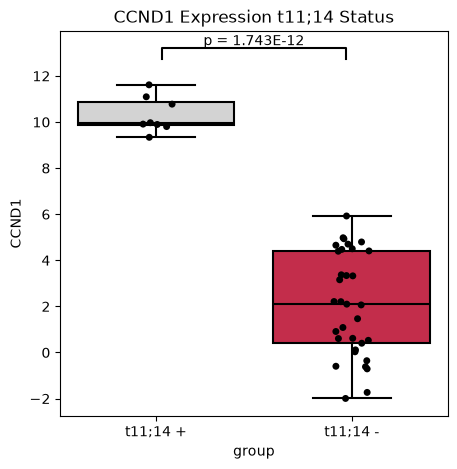

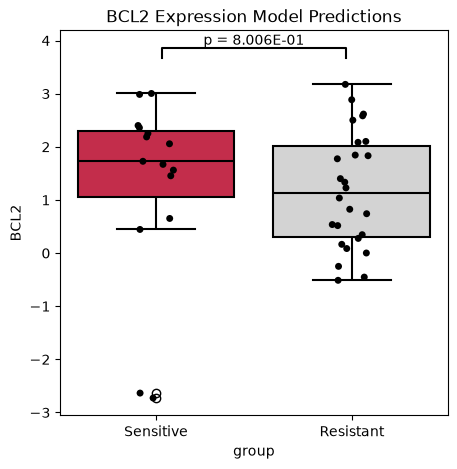

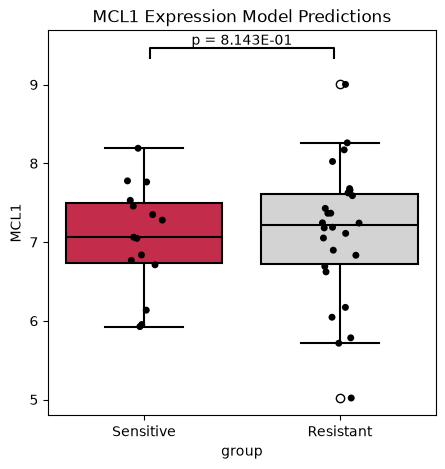

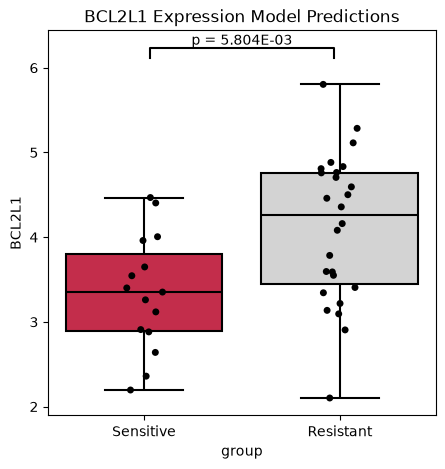

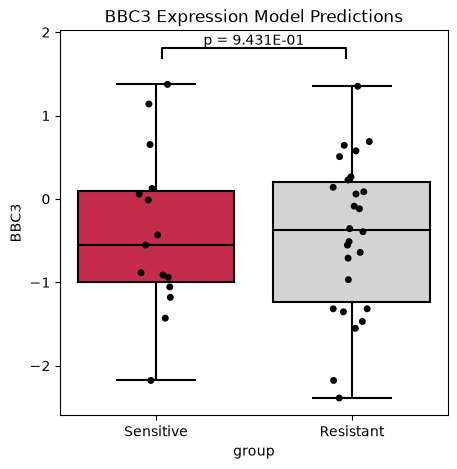

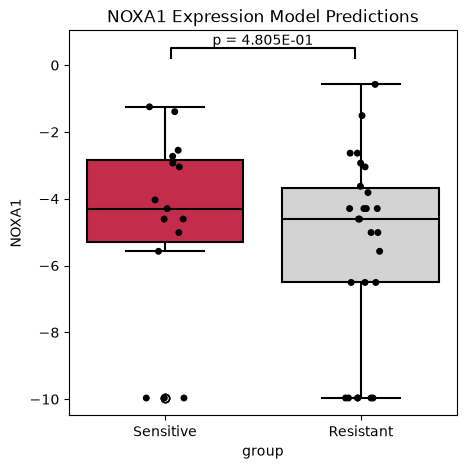

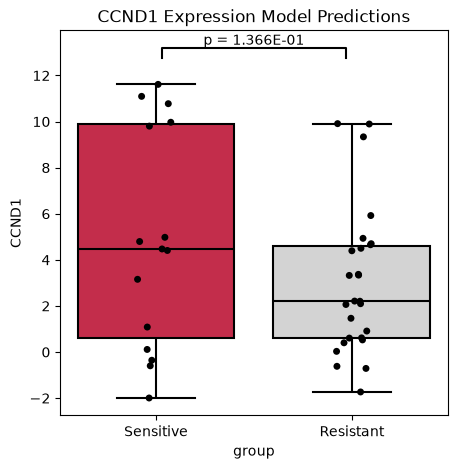

In [9]:
results = []
for adata, label, title in zip(adatas, labels, titles):
    label_mapper = mappers[label]
     
    adata = adata[:, genes_of_interest].copy()

    ctrl_ad = adata[adata.obs[label] == 0].copy()
    exp_ad = adata[adata.obs[label] == 1].copy()
    pvals = []
    statistic = []

    

    # BCL2 - alt greater in sens
    bcl2_test = ttest_ind(np.array(ctrl_ad.to_df()['BCL2']), np.array(exp_ad.to_df()['BCL2']), alternative='two-sided')

    pvals.append(bcl2_test.pvalue)
    statistic.append(bcl2_test.statistic)


   
    # MCL1 - alt less in sens 

    mcl1_test = ttest_ind(ctrl_ad.to_df()['MCL1'], exp_ad.to_df()['MCL1'], alternative='two-sided')
    pvals.append(mcl1_test.pvalue)
    statistic.append(mcl1_test.statistic)
    
    # BCL2L1 - alt less in sens

    bcl2l1_test = ttest_ind(ctrl_ad.to_df()['BCL2L1'], exp_ad.to_df()['BCL2L1'], alternative='two-sided')

    pvals.append(bcl2l1_test.pvalue)
    statistic.append(bcl2l1_test.statistic)


    # BBC3 (PUMA) - alt greater in sens

    bbc3_test = ttest_ind(ctrl_ad.to_df()['BBC3'].to_numpy(), exp_ad.to_df()['BBC3'].to_numpy(), alternative='two-sided')

    pvals.append(bbc3_test.pvalue)
    statistic.append(bbc3_test.statistic)

    # NOXA1 - alt greater in sens

    noxa_test = ttest_ind(ctrl_ad.to_df()['NOXA1'], exp_ad.to_df()['NOXA1'], alternative='two-sided')

    pvals.append(noxa_test.pvalue)
    statistic.append(noxa_test.statistic)


    cd1 = ttest_ind(ctrl_ad.to_df()['CCND1'], exp_ad.to_df()['CCND1'], alternative='two-sided')
    pvals.append(cd1.pvalue)
    statistic.append(cd1.statistic)


    df = pd.DataFrame({'pval':pvals,'stat':statistic, 'gene': genes_of_interest}).set_index('gene')
    df['padj'] = multipletests(pvals, method='fdr_bh')[1]
        
    results.append(df)
    print(df)
    
    # boxplot
    
    expr_df= adata.to_df()


    adata.obs[label] = [label_mapper[y] for y in adata.obs[label]]
    expr_df['group'] = adata.obs[label]

    order = ['t11;14 +', 't11;14 -'] if label == 't11_14' else ['Sensitive', 'Resistant']

    for gene in genes_of_interest:
        c, e, = label_mapper.values()
        annotation = (c, e, f"p = {df['pval'].loc[gene]:.3E}")



        fig, ax = plt.subplots(1, figsize=(5,5))
        plt.title(gene + " Expression " + title) 
        #cols = ['lightgrey', 'crimson']
        cols = ['crimson', 'lightgrey']
        dot_cols = ['k', 'k']
        sns.boxplot(expr_df, y=gene, x='group', hue='group', palette=cols, linecolor='k', linewidth=1.5, order=order) 
        sns.stripplot(expr_df, y=gene, x='group', hue='group', palette=dot_cols, order=order) 


        draw_annotation([annotation])
        plt.savefig(fig_output + title + " " + gene + " " + "mean_expression.png")




                 pval      stat      padj
gene                                     
BCL2/MCL1    0.095597 -1.707942  0.095597
BCL2/BCL2L1  0.048643 -2.035431  0.095597
2.0 0.03
2.0 0.03
                 pval     stat      padj
gene                                    
BCL2/MCL1    0.611094 -0.51264  0.611094
BCL2/BCL2L1  0.401436 -0.84832  0.611094
2.0 0.03
2.0 0.03


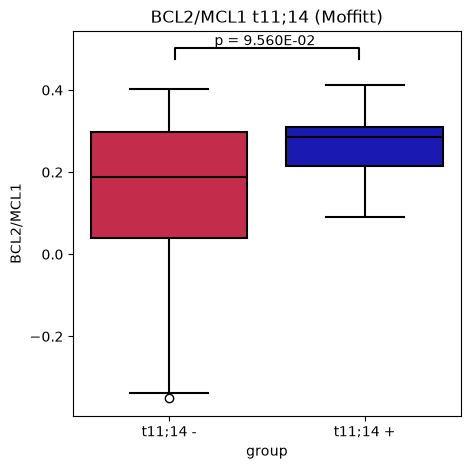

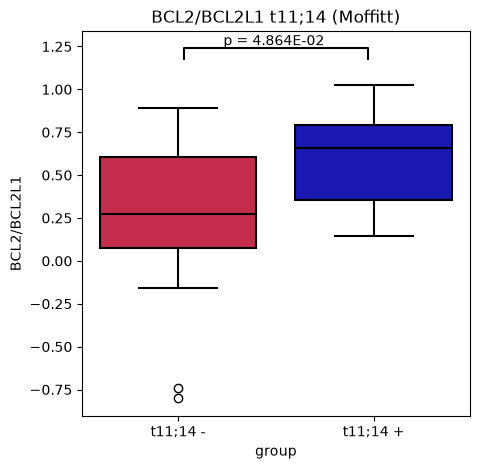

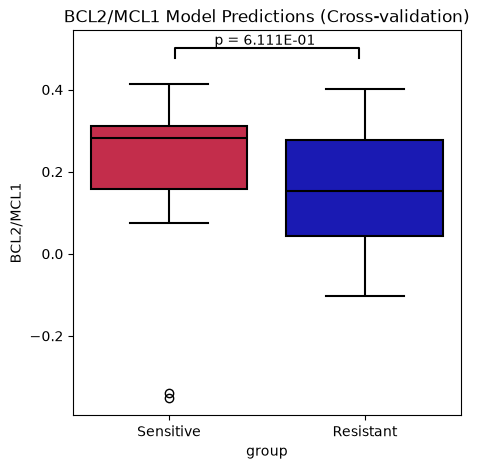

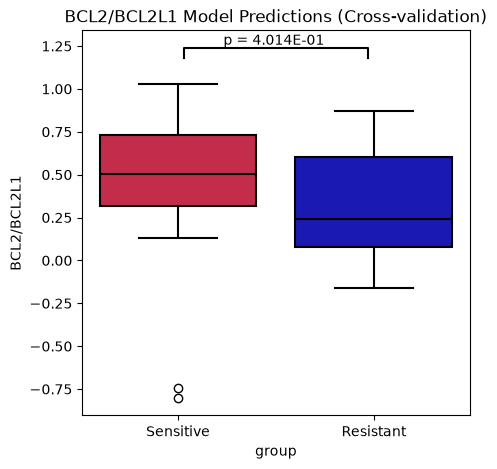

In [10]:
ratios = ["BCL2/MCL1", "BCL2/BCL2L1"]
den_ratios = ["MCL1","BCL2L1"]
titles = ['t11;14 (Moffitt)', "Model Predictions (Cross-validation)", 'Model Predictions (External Validation)']
mappers = {'y_pred': {0: 'Resistant', 1:"Sensitive"},
           't11_14': {0: "t11;14 -", 1:"t11;14 +"}
           }
'mediumblue', 
results = []
for adata, label, title in zip(adatas, labels, titles):
    label_mapper = mappers[label]
     
    adata = adata[:, genes_of_interest].copy()

    ctrl_samples = adata[adata.obs[label] == 0].obs_names
    exp_samples = adata[adata.obs[label] == 1].obs_names

    expr_df= adata.to_df()

    pvals = []
    statistic = []
    
    expr_df['BCL2/MCL1'] = expr_df['BCL2'] / expr_df["MCL1"]

    expr_df['BCL2/BCL2L1'] = expr_df['BCL2'] / expr_df["BCL2L1"]
     
    # BCL2/MCL1 test
    bcl2_mcl1_test = ttest_ind(expr_df['BCL2/MCL1'].loc[ctrl_samples], expr_df['BCL2/MCL1'].loc[exp_samples], alternative='two-sided')
    pvals.append(bcl2_mcl1_test.pvalue)
    statistic.append(bcl2_mcl1_test.statistic)

    # BCL2/BCL2L1 test
    bcl2_bcl2l1_test = ttest_ind(expr_df['BCL2/BCL2L1'].loc[ctrl_samples], expr_df['BCL2/BCL2L1'].loc[exp_samples], alternative='two-sided')
    pvals.append(bcl2_bcl2l1_test.pvalue)
    statistic.append(bcl2_bcl2l1_test.statistic)


    df = pd.DataFrame({'pval':pvals,'stat':statistic, 'gene': ratios}).set_index('gene')

    df['padj'] = multipletests(pvals, method='fdr_bh')[1]
        
    results.append(df)


    print(df)
    # boxplot

    adata.obs[label] = [label_mapper[y] for y in adata.obs[label]]
    expr_df['group'] = adata.obs[label]

    for gene in ratios:
        c, e, = label_mapper.values()
        annotation = (c, e, f'p = {df['pval'].loc[gene]:.3E} ')



        fig, ax = plt.subplots(1, figsize=(5,5))
        plt.title(gene + " " + title) 
        cols = ['crimson', 'mediumblue']
        sns.boxplot(expr_df, y=gene, x='group', hue='group', palette=cols, linecolor='k', linewidth=1.5) 
        draw_annotation([annotation])
    
        







            pval      stat      padj
gene                                
BCL2    0.063486 -2.272082  0.286852
MCL1    0.185996 -1.493198  0.371992
BCL2L1  0.450264  0.807375  0.540316
BBC3    0.339119 -1.038375  0.508678
NOXA1   0.953187  0.061200  0.953187
CCND1   0.095617 -1.975508  0.286852
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03


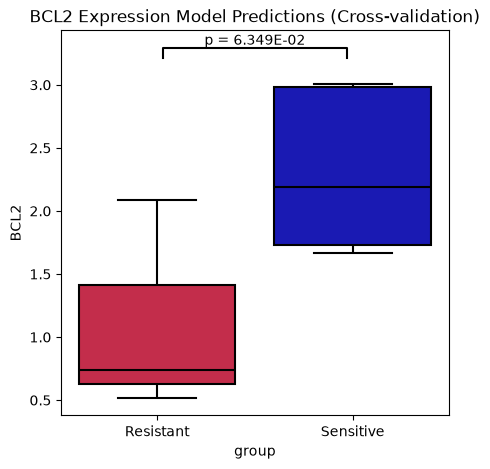

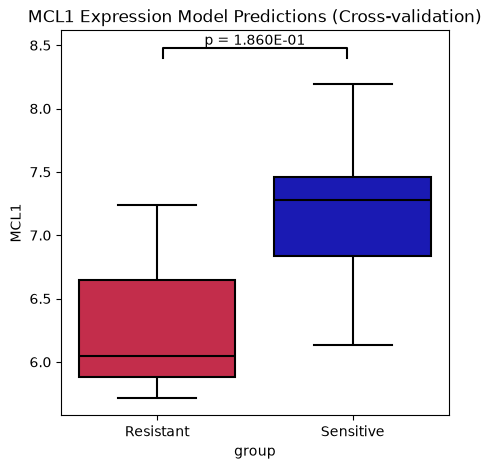

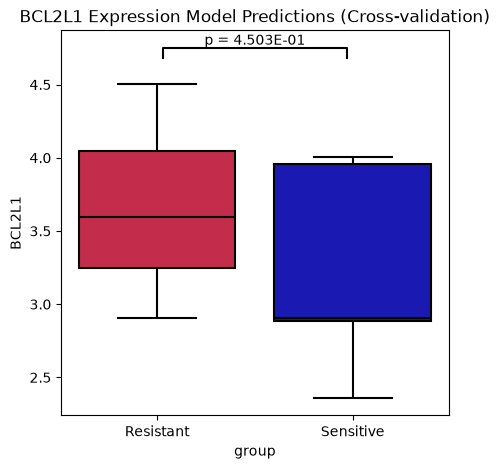

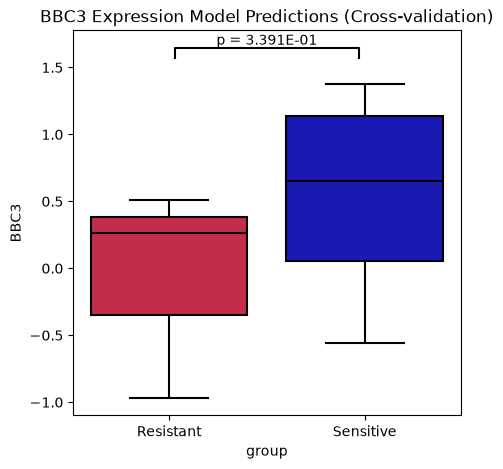

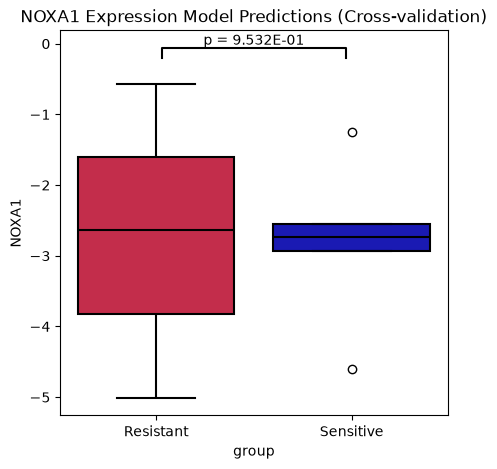

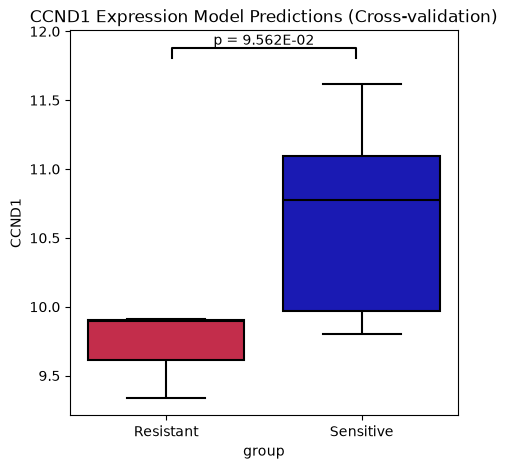

In [11]:
mf_ad = mf_ad[mf_ad.obs['t11_14'] == 1]
adatas = [mf_ad]

labels = ['y_pred']
genes_of_interest = ["BCL2", "MCL1","BCL2L1", "BBC3", "NOXA1", "CCND1"]
titles = ["Model Predictions (Cross-validation)", 'Model Predictions (External Validation)']
mappers = {'y_pred': {0: 'Resistant', 1:"Sensitive"}
           }


results = []
for adata, label, title in zip(adatas, labels, titles):
    label_mapper = mappers[label]
     
    adata = adata[:, genes_of_interest].copy()

    ctrl_ad = adata[adata.obs[label] == 0].copy()
    exp_ad = adata[adata.obs[label] == 1].copy()
    pvals = []
    statistic = []

    

    # BCL2 - alt greater in sens
    bcl2_test = ttest_ind(np.array(ctrl_ad.to_df()['BCL2']), np.array(exp_ad.to_df()['BCL2']), alternative='two-sided')

    pvals.append(bcl2_test.pvalue)
    statistic.append(bcl2_test.statistic)


   
    # MCL1 - alt less in sens 

    mcl1_test = ttest_ind(ctrl_ad.to_df()['MCL1'], exp_ad.to_df()['MCL1'], alternative='two-sided')
    pvals.append(mcl1_test.pvalue)
    statistic.append(mcl1_test.statistic)
    
    # BCL2L1 - alt less in sens

    bcl2l1_test = ttest_ind(ctrl_ad.to_df()['BCL2L1'], exp_ad.to_df()['BCL2L1'], alternative='two-sided')

    pvals.append(bcl2l1_test.pvalue)
    statistic.append(bcl2l1_test.statistic)


    # BBC3 (PUMA) - alt greater in sens

    bbc3_test = ttest_ind(ctrl_ad.to_df()['BBC3'].to_numpy(), exp_ad.to_df()['BBC3'].to_numpy(), alternative='two-sided')

    pvals.append(bbc3_test.pvalue)
    statistic.append(bbc3_test.statistic)

    # NOXA1 - alt greater in sens

    noxa_test = ttest_ind(ctrl_ad.to_df()['NOXA1'], exp_ad.to_df()['NOXA1'], alternative='two-sided')

    pvals.append(noxa_test.pvalue)
    statistic.append(noxa_test.statistic)


    cd1 = ttest_ind(ctrl_ad.to_df()['CCND1'], exp_ad.to_df()['CCND1'], alternative='two-sided')
    pvals.append(cd1.pvalue)
    statistic.append(cd1.statistic)


    df = pd.DataFrame({'pval':pvals,'stat':statistic, 'gene': genes_of_interest}).set_index('gene')
    df['padj'] = multipletests(pvals, method='fdr_bh')[1]
        
    results.append(df)
    print(df)
    
    # boxplot
    
    expr_df= adata.to_df()

    adata.obs[label] = [label_mapper[y] for y in adata.obs[label]]
    expr_df['group'] = adata.obs[label]

    for gene in genes_of_interest:
        c, e, = label_mapper.values()
        annotation = (c, e, f"p = {df['pval'].loc[gene]:.3E}")



        fig, ax = plt.subplots(1, figsize=(5,5))
        plt.title(gene + " Expression " + title) 
        cols = ['crimson', 'mediumblue']
        sns.boxplot(expr_df, y=gene, x='group', hue='group', palette=cols, linecolor='k', linewidth=1.5) 

        draw_annotation([annotation])
        #plt.savefig(fig_output + title + " " + gene + " " + "mean_expression.png")




                                 pval      stat      padj
gene                                                     
BCL2/(Cross-validation)MCL1  0.045048 -2.523918  0.090096
BCL2/BCL2L1                  0.090591 -2.014474  0.090591


ValueError: Could not interpret value `BCL2/(Cross-validation)MCL1` for `y`. An entry with this name does not appear in `data`.

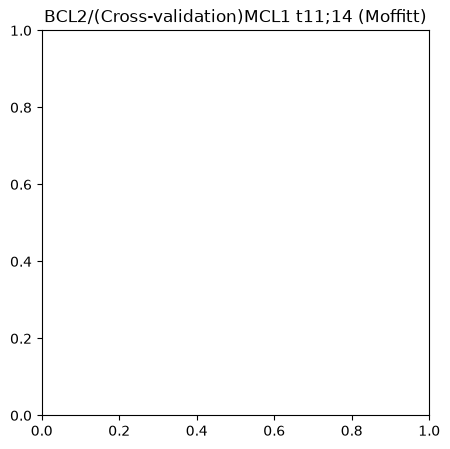

In [12]:
ratios = ["BCL2/(Cross-validation)MCL1", "BCL2/BCL2L1"]
den_ratios = ["MCL1","BCL2L1"]
titles = ['t11;14 (Moffitt)', "Model Predictions (Cross-validation)", 'Model Predictions (External Validation)']
mappers = {'y_pred': {0: 'Resistant', 1:"Sensitive"},
           't11_14': {0: "t11;14 -", 1:"t11;14 +"}
           }

results = []
for adata, label, title in zip(adatas, labels, titles):
    label_mapper = mappers[label]
     
    adata = adata[:, genes_of_interest].copy()

    ctrl_samples = adata[adata.obs[label] == 0].obs_names
    exp_samples = adata[adata.obs[label] == 1].obs_names

    expr_df= adata.to_df()

    pvals = []
    statistic = []
    
    expr_df['BCL2/MCL1'] = expr_df['BCL2'] / expr_df["MCL1"]

    expr_df['BCL2/BCL2L1'] = expr_df['BCL2'] / expr_df["BCL2L1"]
     
    # BCL2/MCL1 test
    bcl2_mcl1_test = ttest_ind(expr_df['BCL2/MCL1'].loc[ctrl_samples], expr_df['BCL2/MCL1'].loc[exp_samples], alternative='two-sided')
    pvals.append(bcl2_mcl1_test.pvalue)
    statistic.append(bcl2_mcl1_test.statistic)

    # BCL2/BCL2L1 test
    bcl2_bcl2l1_test = ttest_ind(expr_df['BCL2/BCL2L1'].loc[ctrl_samples], expr_df['BCL2/BCL2L1'].loc[exp_samples], alternative='two-sided')
    pvals.append(bcl2_bcl2l1_test.pvalue)
    statistic.append(bcl2_bcl2l1_test.statistic)


    df = pd.DataFrame({'pval':pvals,'stat':statistic, 'gene': ratios}).set_index('gene')

    df['padj'] = multipletests(pvals, method='fdr_bh')[1]
        
    results.append(df)


    print(df)
    # boxplot

    adata.obs[label] = [label_mapper[y] for y in adata.obs[label]]
    expr_df['group'] = adata.obs[label]

    for gene in ratios:
        c, e, = label_mapper.values()
        annotation = (c, e, f'p = {df['pval'].loc[gene]:.3E} ')



        fig, ax = plt.subplots(1, figsize=(5,5))
        plt.title(gene + " " + title) 
        cols = ['crimson', 'mediumblue']
        sns.boxplot(expr_df, y=gene, x='group', hue='group', palette=cols, linecolor='k', linewidth=1.5) 
        draw_annotation([annotation])
    
        





